# Assignment 2 Data Exploration Notebook

## Downloading the dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

In [ ]:
!curl -L -o food-delivery-time-prediction.zip\
  https://www.kaggle.com/api/v1/datasets/download/denkuznetz/food-delivery-time-prediction

!unzip -o food-delivery-time-prediction.zip -d Food_Delivery_Times

df_raw = pd.read_csv("Food_Delivery_Times/Food_Delivery_Times.csv")
df_raw.head()

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 11861  100 11861    0     0  30333      0 --:--:-- --:--:-- --:--:-- 30333
Archive:  food-delivery-time-prediction.zip
  inflating: Food_Delivery_Times/Food_Delivery_Times.csv  


,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


## Exploring the Data

In [ ]:
df = df_raw.copy()
df.info()
print(df.isna().sum())
print(df[df.isna().any(axis=1)])
print(df.isna().mean().sort_values(ascending=False))
print(len(df), len(df.dropna()))
# since I would lose too much data if I remove nulls, I will fill nulls with the median

df["Courier_Experience_yrs"] = df["Courier_Experience_yrs"].fillna(df["Courier_Experience_yrs"].median())
for col in ["Weather", "Time_of_Day", "Traffic_Level"]:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df.isna().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    object 
 3   Traffic_Level           970 non-null    object 
 4   Time_of_Day             970 non-null    object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB
Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min

In [ ]:
numerical_cols = [
    "Distance_km",
    "Preparation_Time_min",
    "Courier_Experience_yrs",
    "Delivery_Time_min",
]

print("=== Descriptive Statistics ===")
print(df[numerical_cols].describe().to_string())

print("\n=== Potential Outliers (IQR Method) ===")
for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)][col]

    print(f"\n{col}:")
    print(f"  Lower bound: {lower:.2f}")
    print(f"  Upper bound: {upper:.2f}")
    print(f"  Number of potential outliers: {len(outliers)}")
    print(f"  Outlier values: {sorted(outliers.tolist())}")

=== Descriptive Statistics ===
       Distance_km  Preparation_Time_min  Courier_Experience_yrs  Delivery_Time_min
count  1000.000000           1000.000000             1000.000000        1000.000000
mean     10.059970             16.982000                4.592000          56.732000
std       5.696656              7.204553                2.871198          22.070915
min       0.590000              5.000000                0.000000           8.000000
25%       5.105000             11.000000                2.000000          41.000000
50%      10.190000             17.000000                5.000000          55.500000
75%      15.017500             23.000000                7.000000          71.000000
max      19.990000             29.000000                9.000000         153.000000

=== Potential Outliers (IQR Method) ===

Distance_km:
  Lower bound: -9.76
  Upper bound: 29.89
  Number of potential outliers: 0
  Outlier values: []

Preparation_Time_min:
  Lower bound: -7.00
  Upper bound: 41

In [ ]:
# traffic level remains a single column because each category is more of the same
df["Traffic_Level"] = df["Traffic_Level"].map({"Low": 0, "Medium": 1, "High": 2})
print(df["Traffic_Level"].value_counts(dropna=False))

# the rest of the text data needs to be split into dummy columns because
# the categories are not steps, but actual categories
X = pd.get_dummies(df.drop(columns=["Order_ID", "Delivery_Time_min"]), drop_first=True, dtype=int)
y = df["Delivery_Time_min"]

print(X.shape)             # expect (1000, 13)
print(X.isna().sum().sum())  # expect 0

Traffic_Level
1    420
0    383
2    197
Name: count, dtype: int64
(1000, 13)
0


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# made no difference in accuracy
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Uses ordinary least squares (OLS) by default so I don't to configure that
model = LinearRegression()
model.fit(X_train, y_train)

train_pred = model.predict(X_train)
pred = model.predict(X_test)

print("Training MAE:", mean_absolute_error(y_train, train_pred))
print("Training RMSE:", np.sqrt(mean_squared_error(y_train, train_pred)))
print("Train MAE:", mean_absolute_error(y_train, train_pred))
print("Test MAE:", mean_absolute_error(y_test, pred))


Training MAE: 6.4715337585424075
Training RMSE: 10.433139369174716
Train MAE: 6.4715337585424075
Test MAE: 6.733550605901735


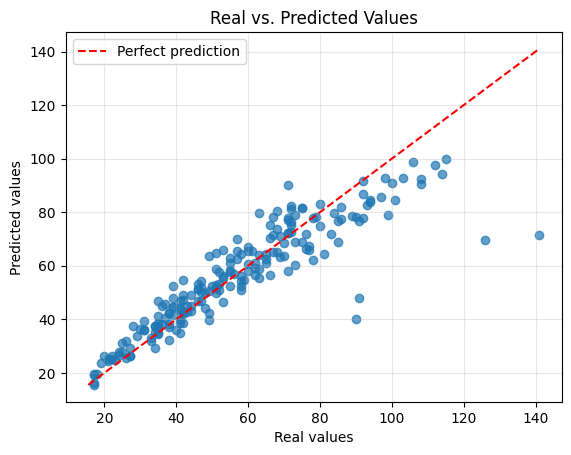

In [ ]:
plt.scatter(y_test, pred, alpha=0.7)

# Perfect prediction reference line
low = min(y_test.min(), pred.min())
high = max(y_test.max(), pred.max())
plt.plot([low, high], [low, high], "r--", label="Perfect prediction")

plt.xlabel("Real values")
plt.ylabel("Predicted values")
plt.title("Real vs. Predicted Values")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()